# Petri dish detection — Petri dish detection

For this component, I wanted to crop the Petri dish out of each image without using any machine learning. I used OpenCV to find the edges and make a square crop. Below I show one image from Y2B_23, one from Y2B_24 and two from Y2B_25, along with my edge checks.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(cv2.__version__)
print(np.__version__)

4.13.0
2.2.0


## Images and setup

The examples are fixed here so I can reproduce the same results. I keep the original images in my local Petri dish detection folder. If I run this from somewhere else, I only need to update `IMAGE_DIR` below.

In [2]:
from pathlib import Path

# I keep the four example images outside Git because the raw datasets are large.
# Works when Jupyter starts from either the task folder or the repo root.
# The old Desktop folder is still supported if I haven't moved the images.
IMAGE_FOLDERS = [
    Path("images"),
    Path("task 2") / "images",
    Path.home() / "Desktop" / "flowerpainting" / "Task2",
]
IMAGE_DIR = next((folder for folder in IMAGE_FOLDERS if folder.is_dir()), IMAGE_FOLDERS[0])

print("Looking for Task 2 images in:", IMAGE_DIR)


## Y2B_23 image

I started with a Y2B_23 image. I use the brightness difference between the dish and the background to locate the edges. Then I adjust the crop to make sure it is square.

Image shape: (3006, 4202, 3)


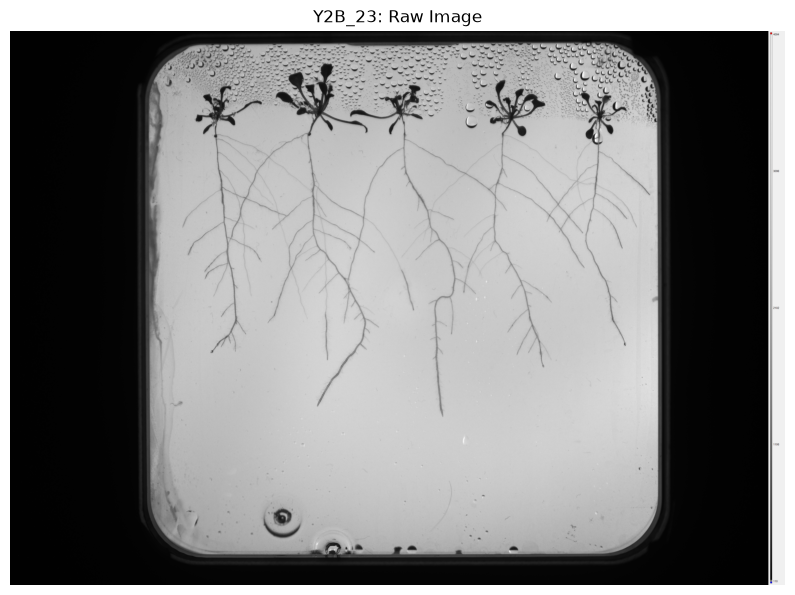

In [3]:
img_23 = cv2.imread(
    str(IMAGE_DIR / "017_43-17-ROOT1-2023-08-08_pvd_OD001_Col0_03-Fish Eye Corrected.png")
)

if img_23 is None:
    raise ValueError("Image could not be loaded. Check the file path.")

print("Image shape:", img_23.shape)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_23, cv2.COLOR_BGR2RGB))
plt.title("Y2B_23: Raw Image")
plt.axis("off")
plt.show()

In [4]:
def extract_petri_dish(image):
    """Find and crop the Petri dish using traditional image processing.

    I use brightness profiles across the middle of the image to avoid the
    curved corners and labels. Otsu thresholding gives an initial box, which
    I adjust into a square crop without resizing the image.

    Args:
        image: Input BGR image read with OpenCV.

    Returns:
        crop: Square BGR crop of the detected Petri dish.
        raw_edges: Original left/top/right/bottom positions in pixels.
        square_edges: Adjusted positions used for the square crop.
        column_profile_smooth: Smoothed column brightness values.
        row_profile_smooth: Smoothed row brightness values.
    """

    if image is None:
        raise ValueError("Input image is None.")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    height, width = gray.shape

    # Use the middle part of the image when measuring brightness.
    # This avoids rounded corners and the white legend on Y2B_23.
    y_start = int(height * 0.20)
    y_end = int(height * 0.80)

    x_start = int(width * 0.20)
    x_end = int(width * 0.80)

    # Median brightness of every image column.
    column_profile = np.median(
        gray[y_start:y_end, :],
        axis=0
    )

    # Median brightness of every image row.
    row_profile = np.median(
        gray[:, x_start:x_end],
        axis=1
    )

    # Smooth the profiles so small objects such as roots,
    # droplets and noise do not create false boundaries.
    column_profile_smooth = cv2.GaussianBlur(
        column_profile.astype(np.float32).reshape(1, -1),
        (31, 1),
        0
    ).ravel()

    row_profile_smooth = cv2.GaussianBlur(
        row_profile.astype(np.float32).reshape(-1, 1),
        (1, 31),
        0
    ).ravel()

    # Convert to uint8 so Otsu thresholding can be used.
    col_uint8 = np.clip(
        column_profile_smooth,
        0,
        255
    ).astype(np.uint8)

    row_uint8 = np.clip(
        row_profile_smooth,
        0,
        255
    ).astype(np.uint8)

    # Automatically separate bright dish area
    # from darker background.
    _, col_binary = cv2.threshold(
        col_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    _, row_binary = cv2.threshold(
        row_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    bright_columns = col_binary > 0
    bright_rows = row_binary > 0

    # Find the largest continuous bright region.
    def largest_region(mask):
        """Return the start and end of the longest bright region."""

        regions = []
        start = None

        for i, value in enumerate(mask):

            if value and start is None:
                start = i

            elif not value and start is not None:
                regions.append((start, i - 1))
                start = None

        if start is not None:
            regions.append((start, len(mask) - 1))

        if len(regions) == 0:
            raise ValueError("No Petri dish region detected.")

        return max(
            regions,
            key=lambda region: region[1] - region[0]
        )

    left, right = largest_region(bright_columns)
    top, bottom = largest_region(bright_rows)

    raw_edges = {
        "left": int(left),
        "top": int(top),
        "right": int(right),
        "bottom": int(bottom)
    }

    # Dimensions detected before forcing square.
    detected_width = right - left + 1
    detected_height = bottom - top + 1

    # The assignment tells us to assume the dish is square.
    # Use the average detected side length so the adjustment
    # is shared between width and height.
    side = int(round(
        (detected_width + detected_height) / 2
    ))

    center_x = (left + right) / 2
    center_y = (top + bottom) / 2

    square_left = int(round(
        center_x - (side - 1) / 2
    ))

    square_top = int(round(
        center_y - (side - 1) / 2
    ))

    square_right = square_left + side - 1
    square_bottom = square_top + side - 1

    # Keep the square inside the original image.
    if square_left < 0:
        shift = -square_left
        square_left += shift
        square_right += shift

    if square_right >= width:
        shift = square_right - width + 1
        square_left -= shift
        square_right -= shift

    if square_top < 0:
        shift = -square_top
        square_top += shift
        square_bottom += shift

    if square_bottom >= height:
        shift = square_bottom - height + 1
        square_top -= shift
        square_bottom -= shift

    square_edges = {
        "left": square_left,
        "top": square_top,
        "right": square_right,
        "bottom": square_bottom
    }

    # Crop using the final square coordinates.
    crop = image[
        square_top:square_bottom + 1,
        square_left:square_right + 1
    ]

    return (
        crop,
        raw_edges,
        square_edges,
        column_profile_smooth,
        row_profile_smooth
    )

In [5]:
crop_23, raw_edges_23, square_edges_23, col_profile_23, row_profile_23 = (
    extract_petri_dish(img_23)
)

print("Originally detected edges:")
print(raw_edges_23)

print("\nFinal square edges:")
print(square_edges_23)

print("\nFinal crop shape:")
print(crop_23.shape)

Originally detected edges:
{'left': 761, 'top': 76, 'right': 3516, 'bottom': 2837}

Final square edges:
{'left': 760, 'top': 78, 'right': 3518, 'bottom': 2836}

Final crop shape:
(2759, 2759, 3)


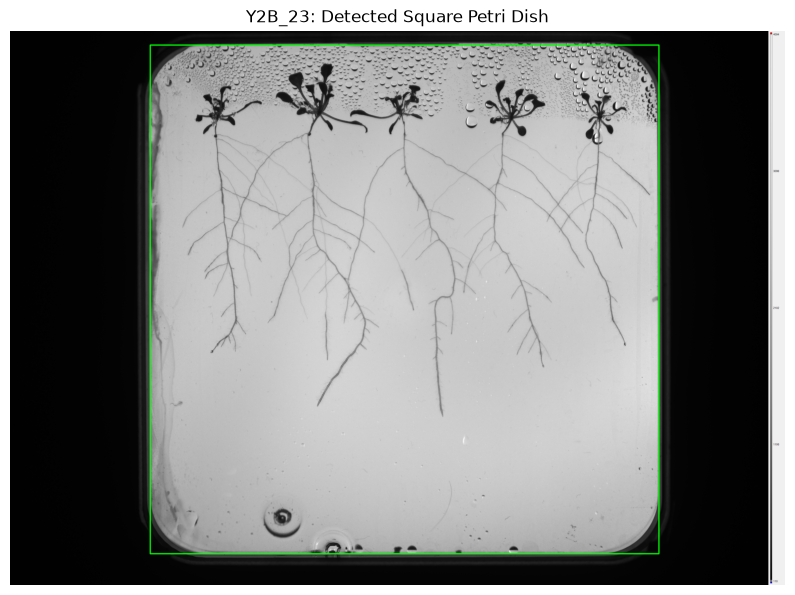

In [6]:
check_23 = img_23.copy()

cv2.rectangle(
    check_23,
    (
        square_edges_23["left"],
        square_edges_23["top"]
    ),
    (
        square_edges_23["right"],
        square_edges_23["bottom"]
    ),
    (0, 255, 0),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(check_23, cv2.COLOR_BGR2RGB))
plt.title("Y2B_23: Detected Square Petri Dish")
plt.axis("off")
plt.show()

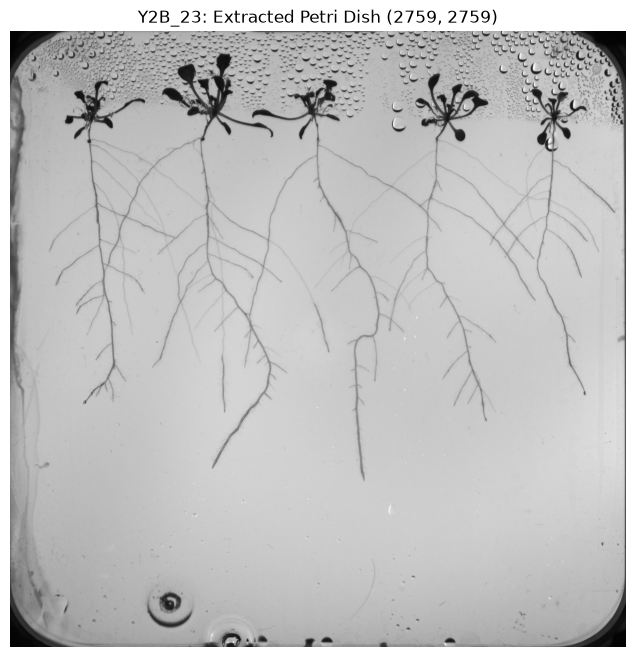

In [7]:
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(crop_23, cv2.COLOR_BGR2RGB))
plt.title(
    f"Y2B_23: Extracted Petri Dish "
    f"{crop_23.shape[:2]}"
)
plt.axis("off")
plt.show()


## Checking the edge positions

I also used Scharr gradients to get a second estimate of where the dish edges are. I compare that estimate with the final square crop on each side. The assignment allows a difference of up to 30 pixels.

This is an automatic edge check, rather than a comparison against manually labelled borders.

In [8]:
def detect_exact_edges(image, coarse_edges, search_radius=80):
    """Estimate dish boundaries using Scharr gradients for a second check.

    I search near the brightness-based edges rather than across the full
    image. This gives a second automatic estimate for comparing the
    four crop edges against the 30-pixel tolerance.

    Args:
        image: Input BGR image.
        coarse_edges: Initial left/top/right/bottom edge coordinates.
        search_radius: Maximum distance to search around each edge.

    Returns:
        A dictionary with estimated left/top/right/bottom edge positions.
        These are automatic estimates, not hand-labelled ground truth.
    """

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Reduce noise before calculating gradients
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Detect vertical intensity changes
    gradient_x = cv2.Scharr(
        blurred,
        cv2.CV_32F,
        1,
        0
    )

    # Detect horizontal intensity changes
    gradient_y = cv2.Scharr(
        blurred,
        cv2.CV_32F,
        0,
        1
    )

    gradient_x = np.abs(gradient_x)
    gradient_y = np.abs(gradient_y)

    left = coarse_edges["left"]
    right = coarse_edges["right"]
    top = coarse_edges["top"]
    bottom = coarse_edges["bottom"]

    dish_width = right - left
    dish_height = bottom - top

    # Only inspect the straight central parts of the dish.
    # This avoids the curved corners.
    y1 = int(top + 0.20 * dish_height)
    y2 = int(top + 0.80 * dish_height)

    x1 = int(left + 0.20 * dish_width)
    x2 = int(left + 0.80 * dish_width)

    # Average vertical-edge strength for every x-coordinate
    vertical_profile = np.mean(
        gradient_x[y1:y2, :],
        axis=0
    )

    # Average horizontal-edge strength for every y-coordinate
    horizontal_profile = np.mean(
        gradient_y[:, x1:x2],
        axis=1
    )

    # Smooth the profiles to suppress small local noise
    vertical_profile = cv2.GaussianBlur(
        vertical_profile.astype(np.float32).reshape(1, -1),
        (31, 1),
        0
    ).ravel()

    horizontal_profile = cv2.GaussianBlur(
        horizontal_profile.astype(np.float32).reshape(-1, 1),
        (1, 31),
        0
    ).ravel()

    def strongest_edge(profile, approximate_position):
        """Pick the strongest nearby gradient peak for one dish edge."""
        start = max(5, approximate_position - search_radius)
        end = min(
            len(profile) - 5,
            approximate_position + search_radius + 1
        )

        local_profile = profile[start:end]

        return start + int(np.argmax(local_profile))

    exact_left = strongest_edge(
        vertical_profile,
        left
    )

    exact_right = strongest_edge(
        vertical_profile,
        right
    )

    exact_top = strongest_edge(
        horizontal_profile,
        top
    )

    exact_bottom = strongest_edge(
        horizontal_profile,
        bottom
    )

    exact_edges = {
        "left": exact_left,
        "top": exact_top,
        "right": exact_right,
        "bottom": exact_bottom
    }

    return exact_edges

In [9]:
exact_edges_23 = detect_exact_edges(
    img_23,
    raw_edges_23
)

print("Brightness-based edges:")
print(raw_edges_23)

print("\nScharr edge coordinates:")
print(exact_edges_23)

print("\nFinal square crop edges:")
print(square_edges_23)

Brightness-based edges:
{'left': 761, 'top': 76, 'right': 3516, 'bottom': 2837}

Scharr edge coordinates:
{'left': 757, 'top': 76, 'right': 3513, 'bottom': 2839}

Final square crop edges:
{'left': 760, 'top': 78, 'right': 3518, 'bottom': 2836}


In [10]:
errors_23 = {}

for edge in exact_edges_23:

    actual_edge = exact_edges_23[edge]
    final_edge = square_edges_23[edge]

    error = abs(final_edge - actual_edge)

    errors_23[edge] = error

    print(f"\n{edge.upper()}")
    print(f"Image edge: {actual_edge}")
    print(f"Final crop: {final_edge}")
    print(f"Difference: {error} pixels")

    if error <= 30:
        print("PASS")
    else:
        print("FAIL")


if all(error <= 30 for error in errors_23.values()):
    print("\nOVERALL: PASS")
    print("All final crop edges are within ±30 pixels.")
else:
    print("\nOVERALL: FAIL")
    print("At least one final crop edge exceeds ±30 pixels.")


LEFT
Image edge: 757
Final crop: 760
Difference: 3 pixels
PASS

TOP
Image edge: 76
Final crop: 78
Difference: 2 pixels
PASS

RIGHT
Image edge: 3513
Final crop: 3518
Difference: 5 pixels
PASS

BOTTOM
Image edge: 2839
Final crop: 2836
Difference: 3 pixels
PASS

OVERALL: PASS
All final crop edges are within ±30 pixels.


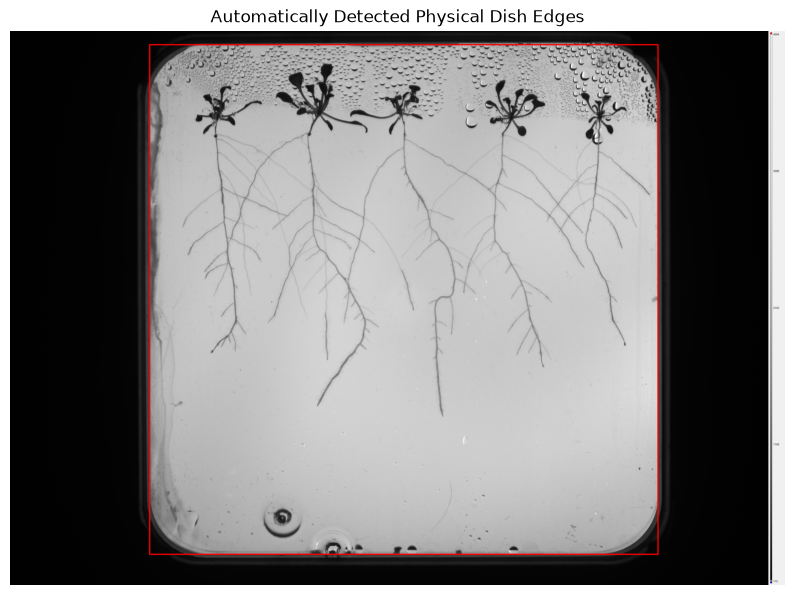

In [11]:
check_exact_23 = img_23.copy()

cv2.rectangle(
    check_exact_23,
    (
        exact_edges_23["left"],
        exact_edges_23["top"]
    ),
    (
        exact_edges_23["right"],
        exact_edges_23["bottom"]
    ),
    (0, 0, 255),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(check_exact_23, cv2.COLOR_BGR2RGB))
plt.title("Automatically Detected Physical Dish Edges")
plt.axis("off")
plt.show()

## Y2B_24 image

I used the same extraction function on this image to see if it would also work on a different year's data. I didn't change the detection settings.

Image shape: (3006, 4202, 3)


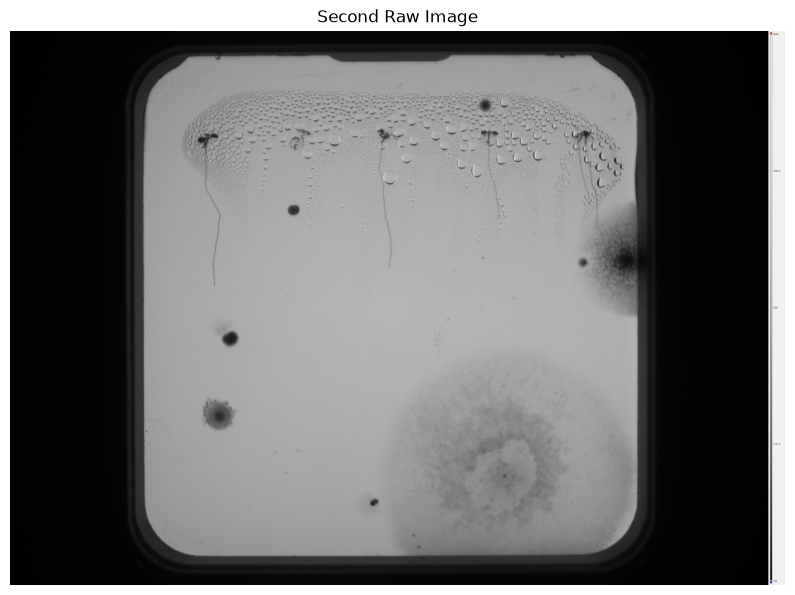

In [12]:
img_2 = cv2.imread(
    str(IMAGE_DIR / "train_Alican_230858_im4.png")
)

if img_2 is None:
    raise ValueError("Second image could not be loaded. Check the file path.")

print("Image shape:", img_2.shape)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_2, cv2.COLOR_BGR2RGB))
plt.title("Second Raw Image")
plt.axis("off")
plt.show()

In [13]:
crop_2, raw_edges_2, square_edges_2, col_profile_2, row_profile_2 = (
    extract_petri_dish(img_2)
)

print("Originally detected edges:")
print(raw_edges_2)

print("\nFinal square edges:")
print(square_edges_2)

print("\nFinal crop shape:")
print(crop_2.shape)

Originally detected edges:
{'left': 724, 'top': 139, 'right': 3401, 'bottom': 2843}

Final square edges:
{'left': 717, 'top': 146, 'right': 3408, 'bottom': 2837}

Final crop shape:
(2692, 2692, 3)


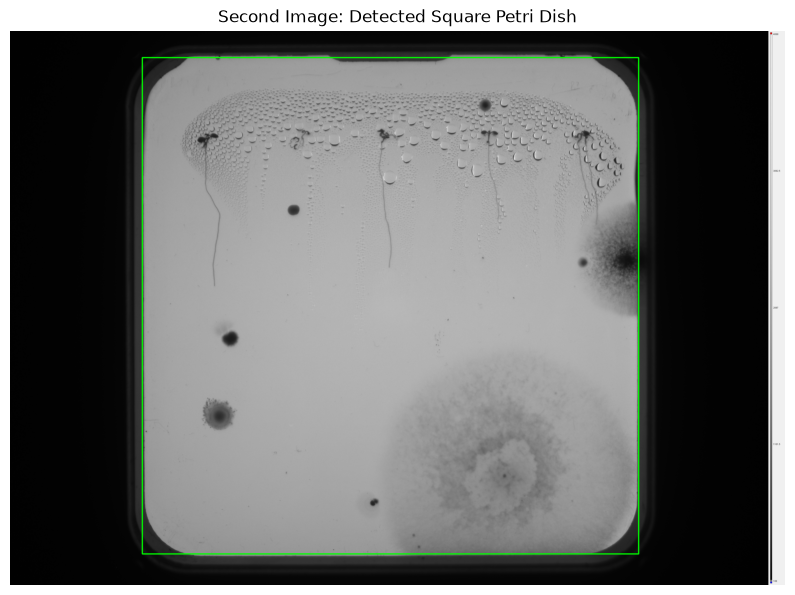

In [15]:
check_2 = img_2.copy()

cv2.rectangle(
    check_2,
    (
        square_edges_2["left"],
        square_edges_2["top"]
    ),
    (
        square_edges_2["right"],
        square_edges_2["bottom"]
    ),
    (0, 255, 0),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(check_2, cv2.COLOR_BGR2RGB))
plt.title("Second Image: Detected Square Petri Dish")
plt.axis("off")
plt.show()

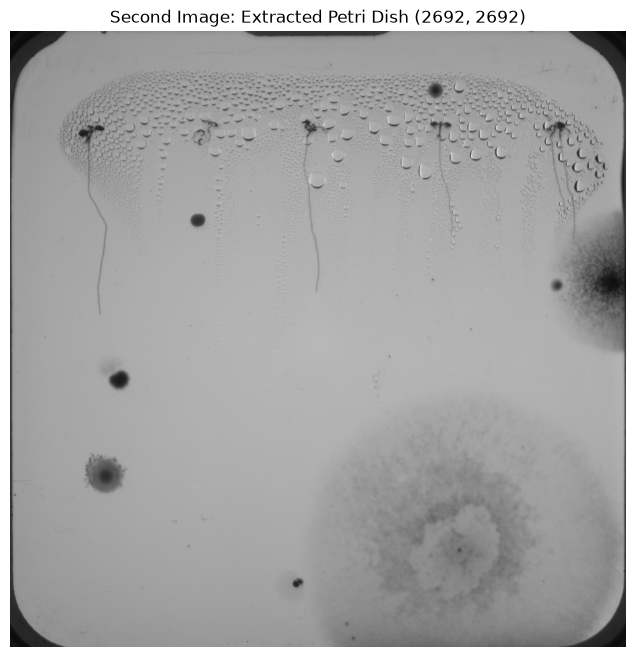

In [16]:
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(crop_2, cv2.COLOR_BGR2RGB))
plt.title(
    f"Second Image: Extracted Petri Dish {crop_2.shape[:2]}"
)
plt.axis("off")
plt.show()

In [17]:
exact_edges_2 = detect_exact_edges(
    img_2,
    raw_edges_2
)

print("Brightness-based edges:")
print(raw_edges_2)

print("\nScharr edge coordinates:")
print(exact_edges_2)

print("\nFinal square crop edges:")
print(square_edges_2)

Brightness-based edges:
{'left': 724, 'top': 139, 'right': 3401, 'bottom': 2843}

Scharr edge coordinates:
{'left': 725, 'top': 134, 'right': 3401, 'bottom': 2847}

Final square crop edges:
{'left': 717, 'top': 146, 'right': 3408, 'bottom': 2837}


In [18]:
errors_2 = {}

for edge in exact_edges_2:

    image_edge = exact_edges_2[edge]
    final_edge = square_edges_2[edge]

    error = abs(final_edge - image_edge)

    errors_2[edge] = error

    print(f"\n{edge.upper()}")
    print(f"Image edge: {image_edge}")
    print(f"Final crop: {final_edge}")
    print(f"Difference: {error} pixels")

    if error <= 30:
        print("PASS")
    else:
        print("FAIL")


if all(error <= 30 for error in errors_2.values()):
    print("\nOVERALL: PASS")
    print("All final crop edges are within ±30 pixels.")
else:
    print("\nOVERALL: FAIL")
    print("At least one final crop edge exceeds ±30 pixels.")


LEFT
Image edge: 725
Final crop: 717
Difference: 8 pixels
PASS

TOP
Image edge: 134
Final crop: 146
Difference: 12 pixels
PASS

RIGHT
Image edge: 3401
Final crop: 3408
Difference: 7 pixels
PASS

BOTTOM
Image edge: 2847
Final crop: 2837
Difference: 10 pixels
PASS

OVERALL: PASS
All final crop edges are within ±30 pixels.


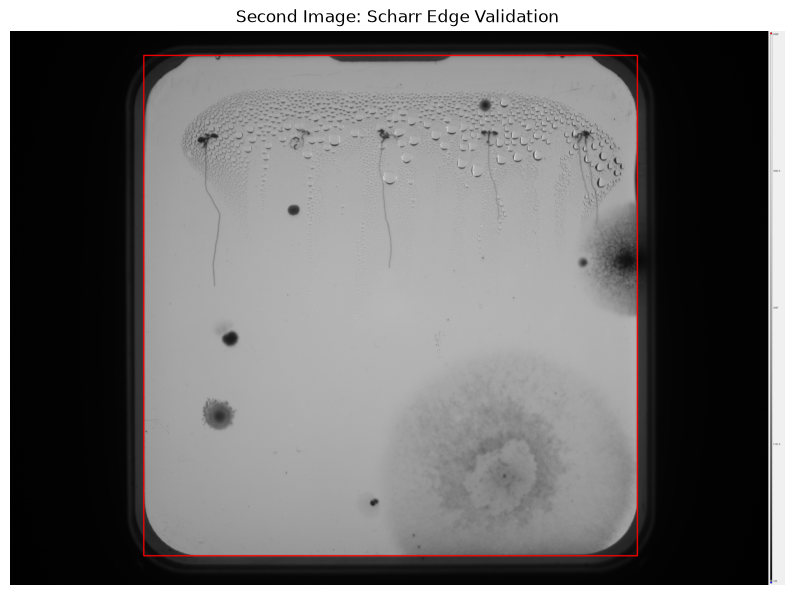

In [19]:
scharr_check_2 = img_2.copy()

cv2.rectangle(
    scharr_check_2,
    (
        exact_edges_2["left"],
        exact_edges_2["top"]
    ),
    (
        exact_edges_2["right"],
        exact_edges_2["bottom"]
    ),
    (0, 0, 255),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(scharr_check_2, cv2.COLOR_BGR2RGB))
plt.title("Second Image: Scharr Edge Validation")
plt.axis("off")
plt.show()

## First Y2B_25 image

Next I tried the same code on Y2B_25. I checked both the square crop and the pixel differences without changing the function.

Image shape: (3006, 4202, 3)


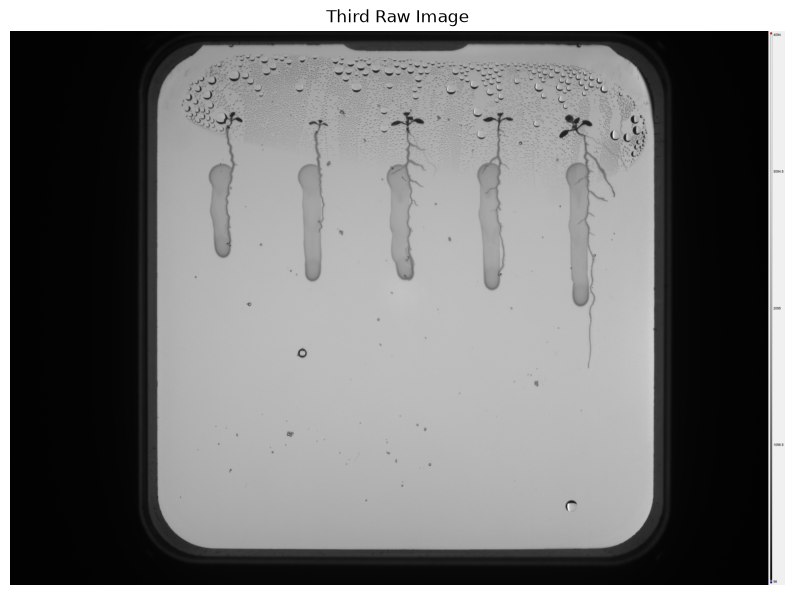

In [20]:
img_3 = cv2.imread(
    str(IMAGE_DIR / "train_Dean_221350_im1.png")
)

if img_3 is None:
    raise ValueError("Third image could not be loaded. Check the file path.")

print("Image shape:", img_3.shape)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_3, cv2.COLOR_BGR2RGB))
plt.title("Third Raw Image")
plt.axis("off")
plt.show()

In [21]:
crop_3, raw_edges_3, square_edges_3, col_profile_3, row_profile_3 = (
    extract_petri_dish(img_3)
)

print("Originally detected edges:")
print(raw_edges_3)

print("\nFinal square edges:")
print(square_edges_3)

print("\nFinal crop shape:")
print(crop_3.shape)

Originally detected edges:
{'left': 796, 'top': 80, 'right': 3494, 'bottom': 2811}

Final square edges:
{'left': 788, 'top': 88, 'right': 3503, 'bottom': 2803}

Final crop shape:
(2716, 2716, 3)


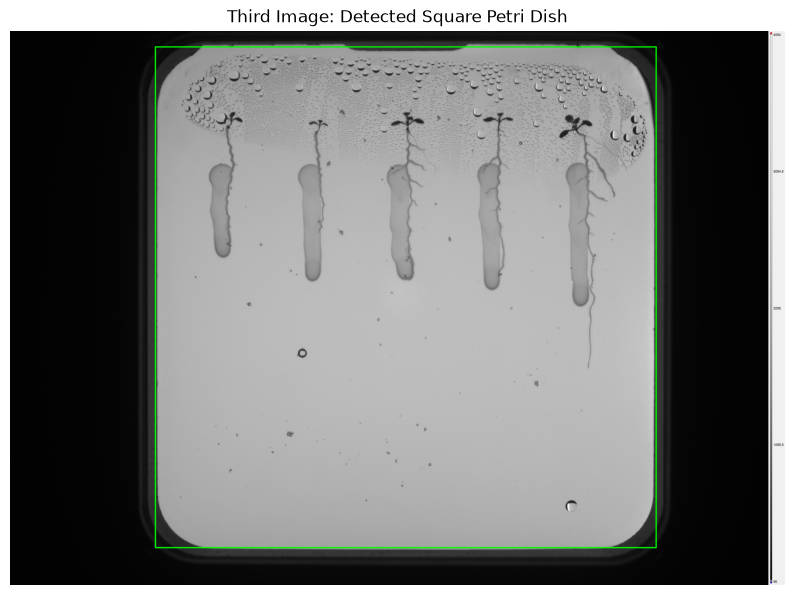

In [22]:
check_3 = img_3.copy()

cv2.rectangle(
    check_3,
    (
        square_edges_3["left"],
        square_edges_3["top"]
    ),
    (
        square_edges_3["right"],
        square_edges_3["bottom"]
    ),
    (0, 255, 0),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(check_3, cv2.COLOR_BGR2RGB))
plt.title("Third Image: Detected Square Petri Dish")
plt.axis("off")
plt.show()

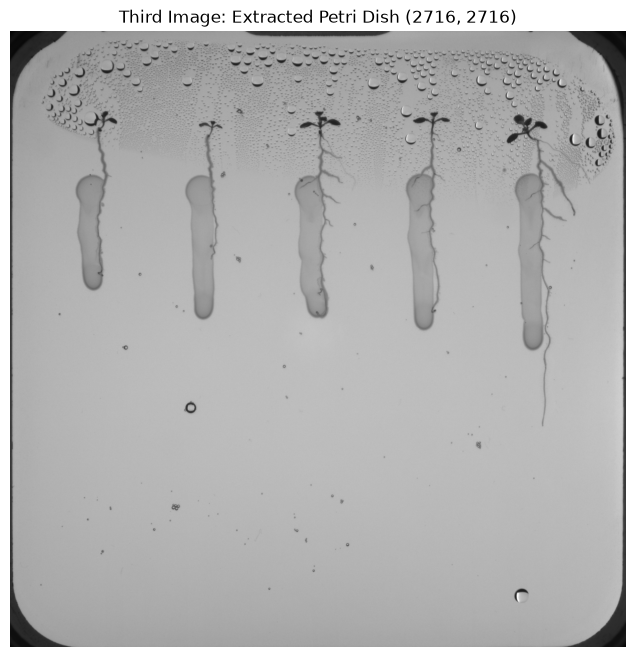

In [23]:
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(crop_3, cv2.COLOR_BGR2RGB))
plt.title(
    f"Third Image: Extracted Petri Dish {crop_3.shape[:2]}"
)
plt.axis("off")
plt.show()

In [24]:
exact_edges_3 = detect_exact_edges(
    img_3,
    raw_edges_3
)

print("Brightness-based edges:")
print(raw_edges_3)

print("\nScharr edge coordinates:")
print(exact_edges_3)

print("\nFinal square crop edges:")
print(square_edges_3)

Brightness-based edges:
{'left': 796, 'top': 80, 'right': 3494, 'bottom': 2811}

Scharr edge coordinates:
{'left': 798, 'top': 75, 'right': 3492, 'bottom': 2812}

Final square crop edges:
{'left': 788, 'top': 88, 'right': 3503, 'bottom': 2803}


In [25]:
errors_3 = {}

for edge in exact_edges_3:

    image_edge = exact_edges_3[edge]
    final_edge = square_edges_3[edge]

    error = abs(final_edge - image_edge)

    errors_3[edge] = error

    print(f"\n{edge.upper()}")
    print(f"Image edge: {image_edge}")
    print(f"Final crop: {final_edge}")
    print(f"Difference: {error} pixels")

    if error <= 30:
        print("PASS")
    else:
        print("FAIL")


if all(error <= 30 for error in errors_3.values()):
    print("\nOVERALL: PASS")
    print("All final crop edges are within ±30 pixels.")
else:
    print("\nOVERALL: FAIL")
    print("At least one final crop edge exceeds ±30 pixels.")


LEFT
Image edge: 798
Final crop: 788
Difference: 10 pixels
PASS

TOP
Image edge: 75
Final crop: 88
Difference: 13 pixels
PASS

RIGHT
Image edge: 3492
Final crop: 3503
Difference: 11 pixels
PASS

BOTTOM
Image edge: 2812
Final crop: 2803
Difference: 9 pixels
PASS

OVERALL: PASS
All final crop edges are within ±30 pixels.


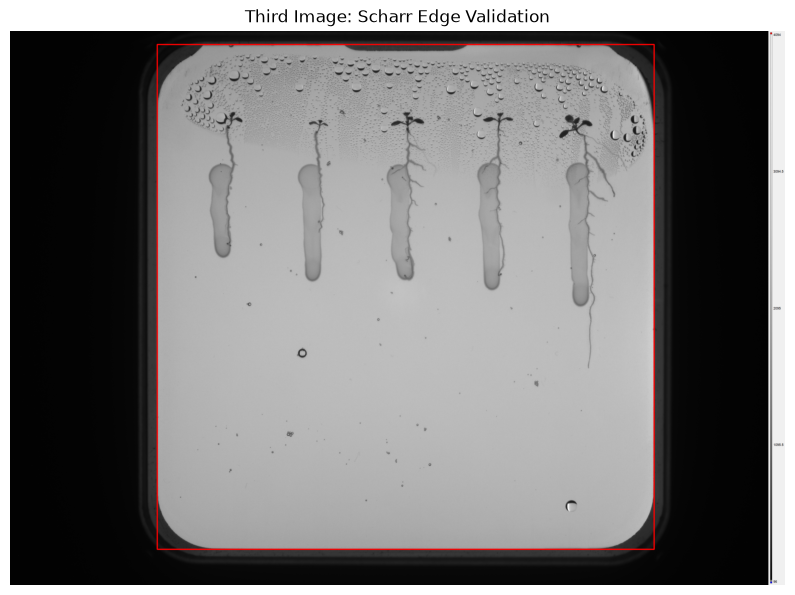

In [26]:
scharr_check_3 = img_3.copy()

cv2.rectangle(
    scharr_check_3,
    (
        exact_edges_3["left"],
        exact_edges_3["top"]
    ),
    (
        exact_edges_3["right"],
        exact_edges_3["bottom"]
    ),
    (0, 0, 255),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(scharr_check_3, cv2.COLOR_BGR2RGB))
plt.title("Third Image: Scharr Edge Validation")
plt.axis("off")
plt.show()

## Second Y2B_25 image

This is another image from Y2B_25. I kept the method the same again and checked the crop and all four edges.

Image shape: (3006, 4202, 3)


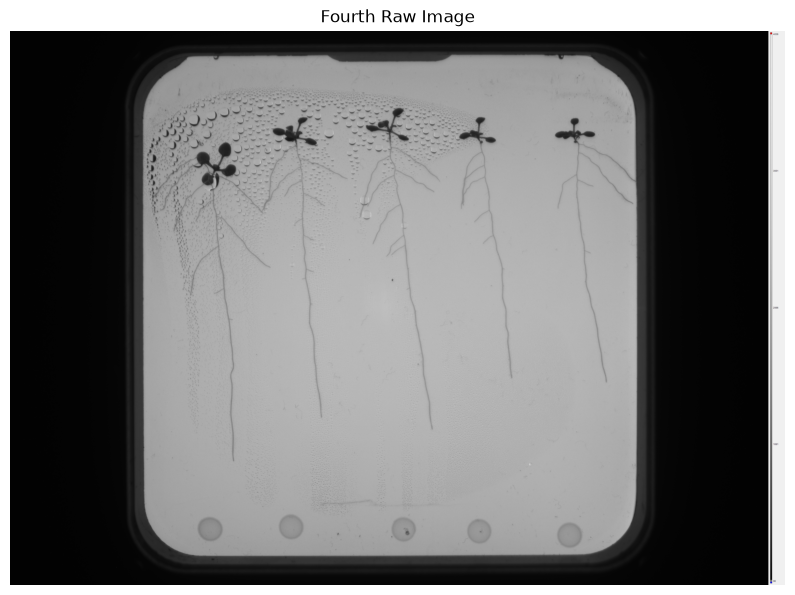

In [27]:
img_4 = cv2.imread(
    str(IMAGE_DIR / "train_Jason_242140_im1.png")
)

if img_4 is None:
    raise ValueError("Fourth image could not be loaded. Check the file path.")

print("Image shape:", img_4.shape)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_4, cv2.COLOR_BGR2RGB))
plt.title("Fourth Raw Image")
plt.axis("off")
plt.show()

In [28]:
crop_4, raw_edges_4, square_edges_4, col_profile_4, row_profile_4 = (
    extract_petri_dish(img_4)
)

print("Originally detected edges:")
print(raw_edges_4)

print("\nFinal square edges:")
print(square_edges_4)

print("\nFinal crop shape:")
print(crop_4.shape)

Originally detected edges:
{'left': 721, 'top': 139, 'right': 3401, 'bottom': 2847}

Final square edges:
{'left': 714, 'top': 146, 'right': 3408, 'bottom': 2840}

Final crop shape:
(2695, 2695, 3)


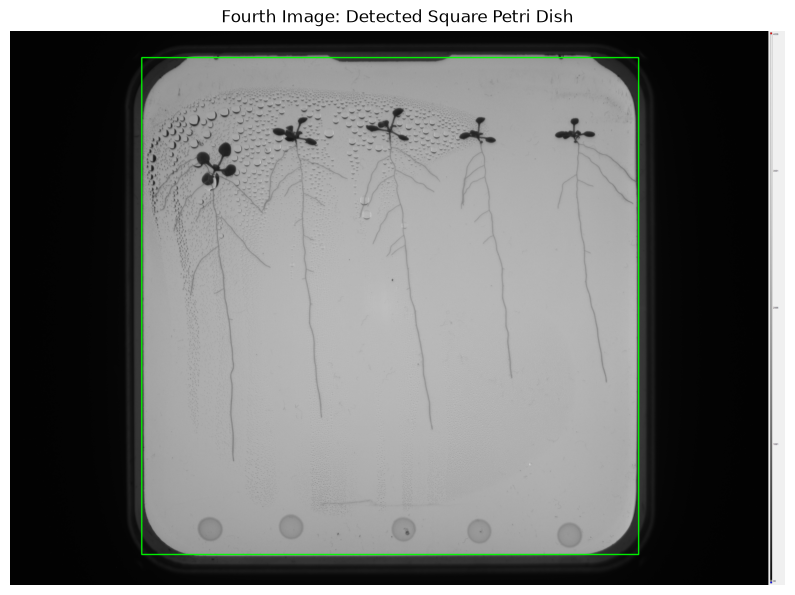

In [29]:
check_4 = img_4.copy()

cv2.rectangle(
    check_4,
    (
        square_edges_4["left"],
        square_edges_4["top"]
    ),
    (
        square_edges_4["right"],
        square_edges_4["bottom"]
    ),
    (0, 255, 0),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(check_4, cv2.COLOR_BGR2RGB))
plt.title("Fourth Image: Detected Square Petri Dish")
plt.axis("off")
plt.show()

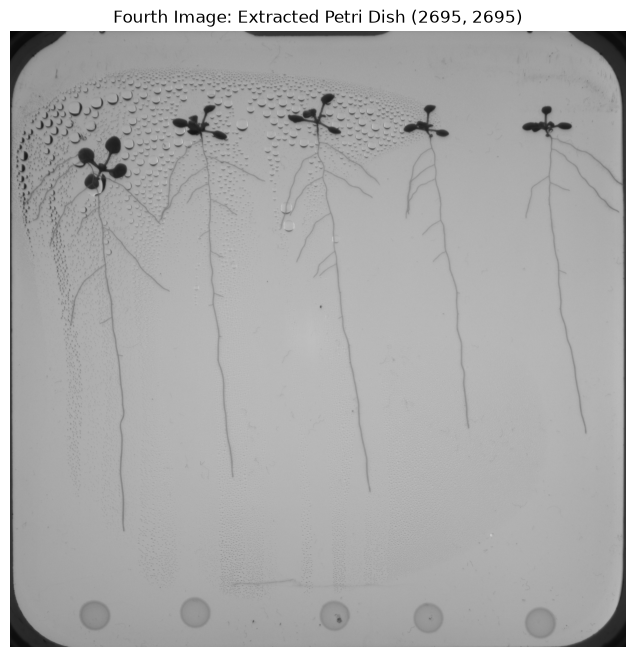

In [30]:
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(crop_4, cv2.COLOR_BGR2RGB))
plt.title(
    f"Fourth Image: Extracted Petri Dish {crop_4.shape[:2]}"
)
plt.axis("off")
plt.show()

In [31]:
exact_edges_4 = detect_exact_edges(
    img_4,
    raw_edges_4
)

print("Brightness-based edges:")
print(raw_edges_4)

print("\nScharr edge coordinates:")
print(exact_edges_4)

print("\nFinal square crop edges:")
print(square_edges_4)

Brightness-based edges:
{'left': 721, 'top': 139, 'right': 3401, 'bottom': 2847}

Scharr edge coordinates:
{'left': 723, 'top': 134, 'right': 3398, 'bottom': 2847}

Final square crop edges:
{'left': 714, 'top': 146, 'right': 3408, 'bottom': 2840}


In [32]:
errors_4 = {}

for edge in exact_edges_4:

    image_edge = exact_edges_4[edge]
    final_edge = square_edges_4[edge]

    error = abs(final_edge - image_edge)

    errors_4[edge] = error

    print(f"\n{edge.upper()}")
    print(f"Image edge: {image_edge}")
    print(f"Final crop: {final_edge}")
    print(f"Difference: {error} pixels")

    if error <= 30:
        print("PASS")
    else:
        print("FAIL")


if all(error <= 30 for error in errors_4.values()):
    print("\nOVERALL: PASS")
    print("All final crop edges are within ±30 pixels.")
else:
    print("\nOVERALL: FAIL")
    print("At least one final crop edge exceeds ±30 pixels.")


LEFT
Image edge: 723
Final crop: 714
Difference: 9 pixels
PASS

TOP
Image edge: 134
Final crop: 146
Difference: 12 pixels
PASS

RIGHT
Image edge: 3398
Final crop: 3408
Difference: 10 pixels
PASS

BOTTOM
Image edge: 2847
Final crop: 2840
Difference: 7 pixels
PASS

OVERALL: PASS
All final crop edges are within ±30 pixels.


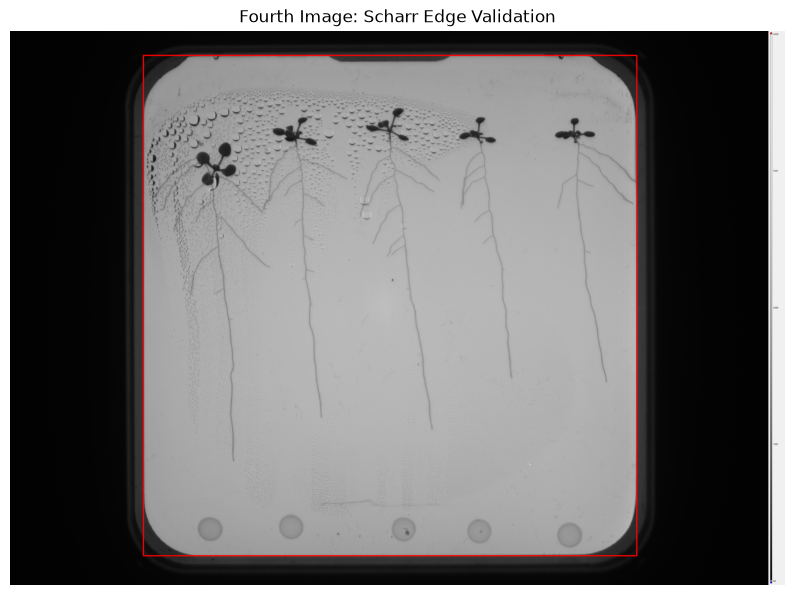

In [33]:
scharr_check_4 = img_4.copy()

cv2.rectangle(
    scharr_check_4,
    (
        exact_edges_4["left"],
        exact_edges_4["top"]
    ),
    (
        exact_edges_4["right"],
        exact_edges_4["bottom"]
    ),
    (0, 0, 255),
    5
)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(scharr_check_4, cv2.COLOR_BGR2RGB))
plt.title("Fourth Image: Scharr Edge Validation")
plt.axis("off")
plt.show()

## Checking the four examples together

I ran both functions on the four images again in one loop. This is mainly so I could check the crop size and the edge differences in the same way for every example.

In [34]:
image_paths = {
    "Image 1": str(IMAGE_DIR / "017_43-17-ROOT1-2023-08-08_pvd_OD001_Col0_03-Fish Eye Corrected.png"),
    "Image 2": str(IMAGE_DIR / "train_Alican_230858_im4.png"),
    "Image 3": str(IMAGE_DIR / "train_Dean_221350_im1.png"),
    "Image 4": str(IMAGE_DIR / "train_Jason_242140_im1.png")
}

results = {}

for name, path in image_paths.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Load image
    image = cv2.imread(path)

    if image is None:
        print("FAIL - Image could not be loaded.")
        continue

    # Run the SAME Petri dish extraction function
    crop, raw_edges, square_edges, col_profile, row_profile = (
        extract_petri_dish(image)
    )

    # Run Scharr sanity check
    exact_edges = detect_exact_edges(
        image,
        raw_edges
    )

    # --------------------------------------------------
    # Requirement 2: ±30 pixel check
    # --------------------------------------------------

    errors = {}

    for edge in exact_edges:

        error = abs(
            square_edges[edge] - exact_edges[edge]
        )

        errors[edge] = error

    pixel_pass = all(
        error <= 30
        for error in errors.values()
    )

    # --------------------------------------------------
    # Requirement 4: square output
    # --------------------------------------------------

    square_pass = (
        crop.shape[0] == crop.shape[1]
    )

    # Save results
    results[name] = {
        "image": image,
        "crop": crop,
        "raw_edges": raw_edges,
        "square_edges": square_edges,
        "exact_edges": exact_edges,
        "errors": errors,
        "pixel_pass": pixel_pass,
        "square_pass": square_pass
    }

    # --------------------------------------------------
    # Print results
    # --------------------------------------------------

    print("\nFinal crop shape:")
    print(crop.shape)

    print("\nPixel differences:")

    for edge, error in errors.items():
        status = "PASS" if error <= 30 else "FAIL"

        print(
            f"{edge}: {error} pixels - {status}"
        )

    print("\nSquare requirement:")

    if square_pass:
        print("PASS - Output is square.")
    else:
        print("FAIL - Output is not square.")

    print("\n±30 pixel requirement:")

    if pixel_pass:
        print("PASS - All edges are within ±30 pixels.")
    else:
        print("FAIL - At least one edge exceeds ±30 pixels.")


Image 1

Final crop shape:
(2759, 2759, 3)

Pixel differences:
left: 3 pixels - PASS
top: 2 pixels - PASS
right: 5 pixels - PASS
bottom: 3 pixels - PASS

Square requirement:
PASS - Output is square.

±30 pixel requirement:
PASS - All edges are within ±30 pixels.

Image 2

Final crop shape:
(2692, 2692, 3)

Pixel differences:
left: 8 pixels - PASS
top: 12 pixels - PASS
right: 7 pixels - PASS
bottom: 10 pixels - PASS

Square requirement:
PASS - Output is square.

±30 pixel requirement:
PASS - All edges are within ±30 pixels.

Image 3

Final crop shape:
(2716, 2716, 3)

Pixel differences:
left: 10 pixels - PASS
top: 13 pixels - PASS
right: 11 pixels - PASS
bottom: 9 pixels - PASS

Square requirement:
PASS - Output is square.

±30 pixel requirement:
PASS - All edges are within ±30 pixels.

Image 4

Final crop shape:
(2695, 2695, 3)

Pixel differences:
left: 9 pixels - PASS
top: 12 pixels - PASS
right: 10 pixels - PASS
bottom: 7 pixels - PASS

Square requirement:
PASS - Output is square.



In [35]:
print("\n" + "=" * 60)
print("OVERALL TASK 2 CHECK")
print("=" * 60)

all_loaded = len(results) == 4

all_square = (
    all(result["square_pass"] for result in results.values())
    if all_loaded
    else False
)

all_pixels = (
    all(result["pixel_pass"] for result in results.values())
    if all_loaded
    else False
)

print("\n1. Traditional CV only:")
print("PASS - No ML/DL model is used.")

print("\n2. Edges within ±30 pixels:")
print("PASS" if all_pixels else "FAIL")

print("\n3. Same code works on all four images:")
print("PASS" if all_loaded else "FAIL")

print("\n4. All outputs are square:")
print("PASS" if all_square else "FAIL")

print("\n5. Four required outputs available:")
print("PASS" if all_loaded else "FAIL")


OVERALL TASK 2 CHECK

1. Traditional CV only:
PASS - No ML/DL model is used.

2. Edges within ±30 pixels:
PASS

3. Same code works on all four images:
PASS

4. All outputs are square:
PASS

5. Four required outputs available:
PASS


## Final comparison

Here are the four original images next to their square crops. The largest difference from the Scharr edge estimate was 13 pixels in these examples, and all four crops were square. I kept the code and settings the same across the three years.

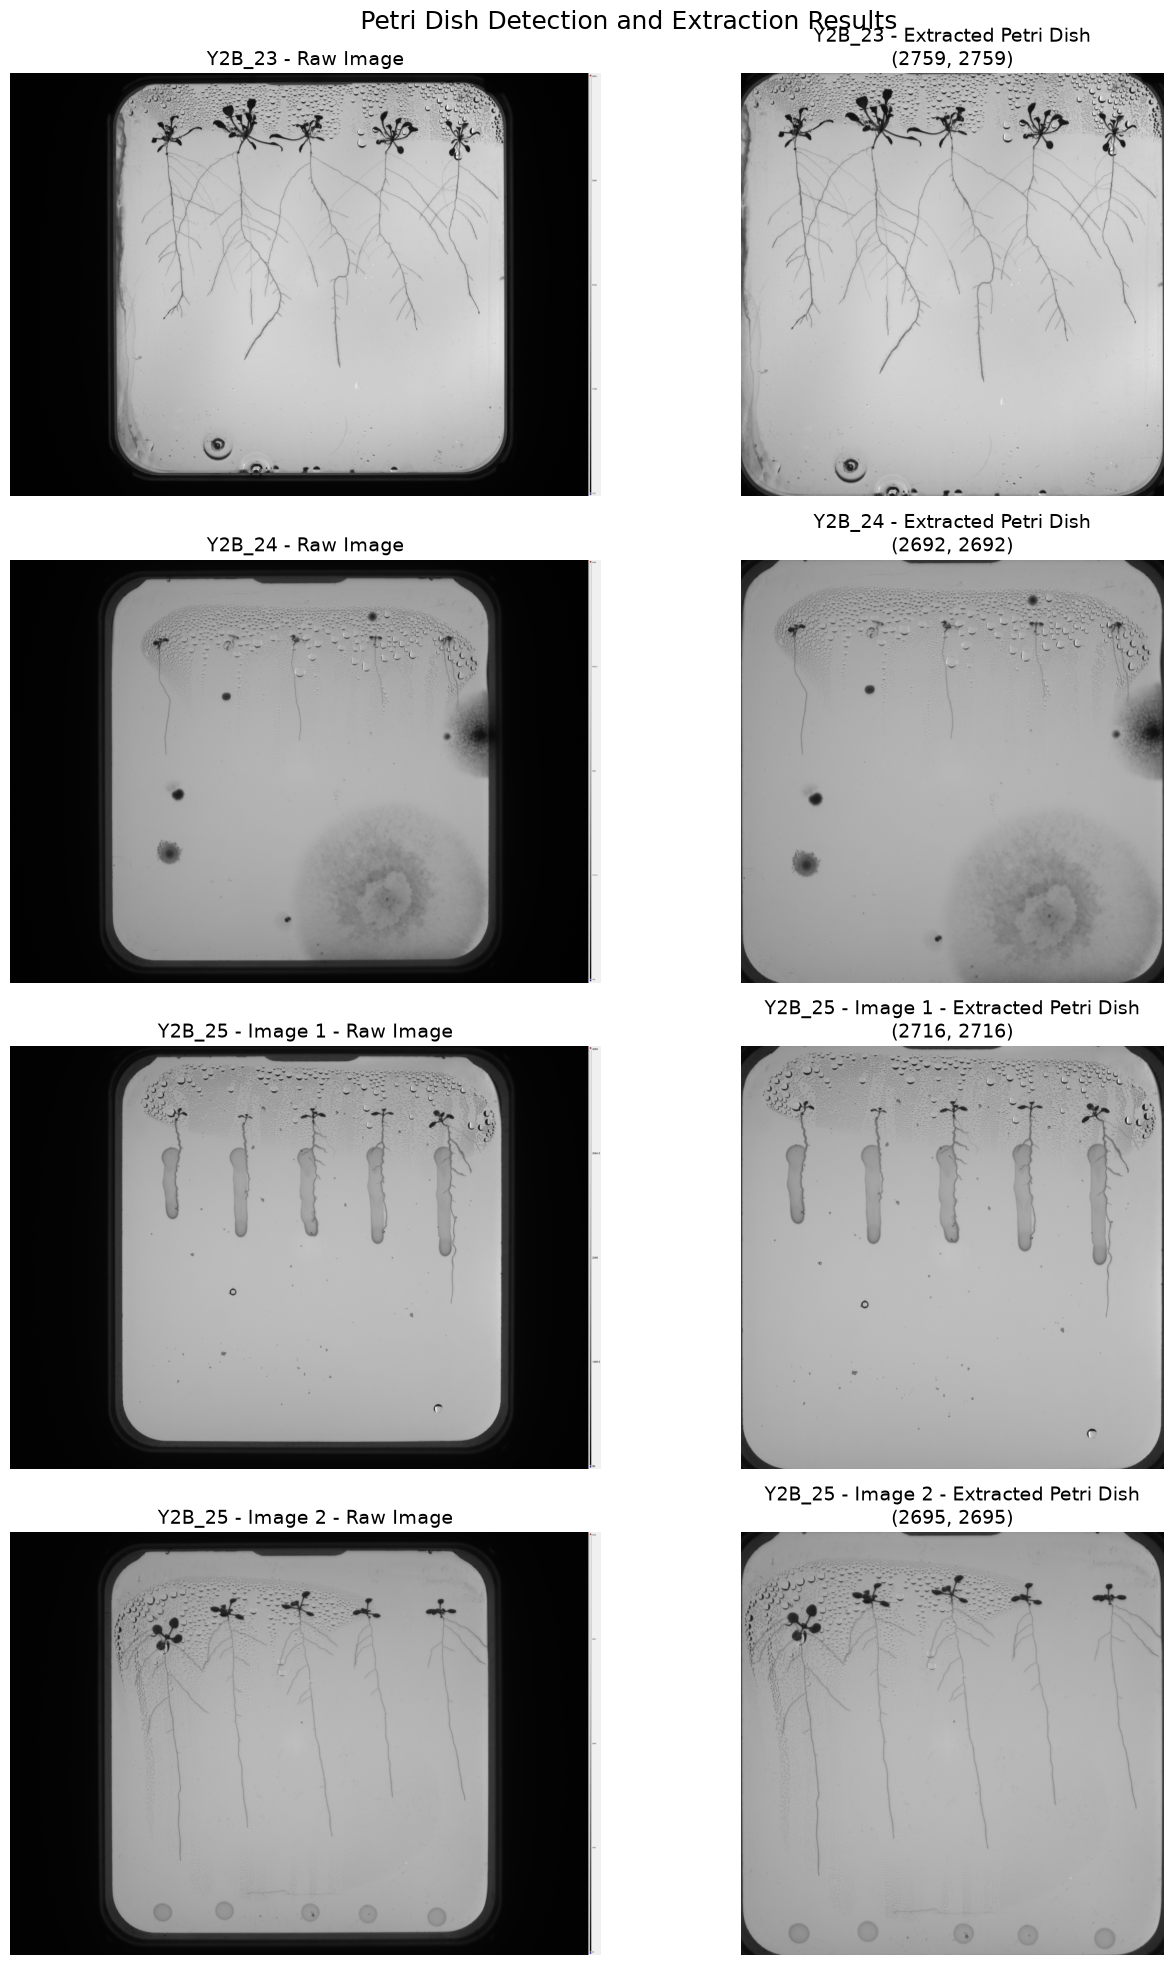

In [36]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))

raw_images = [
    img_23,
    img_2,
    img_3,
    img_4
]

cropped_images = [
    crop_23,
    crop_2,
    crop_3,
    crop_4
]

names = [
    "Y2B_23",
    "Y2B_24",
    "Y2B_25 - Image 1",
    "Y2B_25 - Image 2"
]

for i in range(4):

    # Raw image
    axes[i, 0].imshow(
        cv2.cvtColor(raw_images[i], cv2.COLOR_BGR2RGB)
    )

    axes[i, 0].set_title(
        f"{names[i]} - Raw Image",
        fontsize=14
    )

    axes[i, 0].axis("off")

    # Cropped Petri dish
    axes[i, 1].imshow(
        cv2.cvtColor(cropped_images[i], cv2.COLOR_BGR2RGB)
    )

    height, width = cropped_images[i].shape[:2]

    axes[i, 1].set_title(
        f"{names[i]} - Extracted Petri Dish\n"
        f"({height}, {width})",
        fontsize=14
    )

    axes[i, 1].axis("off")


plt.suptitle(
    "Petri Dish Detection and Extraction Results",
    fontsize=18
)

plt.tight_layout()
plt.show()